<a href="https://colab.research.google.com/github/eyramg/Walmart-Hurricane-Project/blob/main/notebooks/Copy_of_2026_10_23_%E2%80%94_Midterm_Checkpoint_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Midterm Checkpoint

**Lab — 2026-10-23 · Fall 2026**  

---

## Lab 09 — Midterm checkpoint, week 1 of 3

**What you submit: the link to your team's main repo. Only that.** One submission per team. Do not upload separate files.

Put this notebook in the repo (the `notebooks/` folder is fine) and push it, so everything we check is in one place.

**You do not have to fill this all out.** It is a checkpoint, not a finished project. Skip any section you have not started and write "not started" next to it. What we must see is:

1. **Your charter**, committed to the repo
2. **Any progress** you have made, with code that ran and output you can point at

Start with the team setup, then work down the same eight things we listed at Monday's kickoff, as far as you have gotten. This is graded on evidence, not on intentions.

The purpose is to catch a stalled team while there is still time to unstall it. If something is not working, say so here plainly. A checkpoint that honestly reports "the API join is not working and here is the error" is worth more than one that claims progress that does not exist, and it gets you help on Monday.

### Team setup

This part is required. Fill it in once for the whole team.

You need:

- Your team name, and every member with a GitHub handle (2 to 4 people)
- A link to your team's **main repo**. This is the one link you submit.
- A link to `CHARTER.md` in that repo, the page on GitHub, not a file on someone's laptop

Nice to have, and also in your charter: this week's notebook owner, your meeting time, and the five worst problems in the data from the profile you ran on Monday. Be specific: "`unit_price` is stored as text and some values start with `$`" beats "prices are messy."

In [ ]:

team_setup = {
    'team_name': 'World Travelers',

    'members': [
        {'name': 'Shreya', 'github': 'shreyashan-git'},
        {'name': 'Smera', 'github': 'smerashanmugan'},
        {'name': 'Eyram', 'github': 'eyramg'},
    ],

    'repo_url': 'https://github.com/eyramg/Walmart-Hurricane-Project',

    'charter_url': 'https://github.com/eyramg/Walmart-Hurricane-Project/blob/main/CHARTER.md',

    'notebook_owner_this_week': 'Shreya',

    'meeting_time': 'Fridays at 6 PM',

    'five_worst_problems': [
        'The dataset contains 30 exact duplicate rows, which could inflate transaction counts.',

        'The timestamp column has 886 missing values (3.5%), which could affect daily sales analysis.',

        'The unit_price column is stored as text instead of a numeric data type and needs cleaning before revenue calculations.',

        'There are 45 unique SKUs but 63 distinct product names, suggesting possible product naming inconsistencies.',

        'The category column contains 37 distinct values that need to be checked for inconsistent spelling or formatting.'
    ],
}


def check_team(t, quiet=False):
    def real(v):
        return isinstance(v, str) and v.strip() != '' and not v.startswith('TODO')

    required = {
        'team name': real(t['team_name']),

        '2 to 4 members, each with a name and GitHub handle':
            2 <= len(t['members']) <= 4
            and all(
                real(m['name']) and real(m['github'])
                for m in t['members']
            ),

        'main repo link':
            real(t['repo_url'])
            and t['repo_url'].startswith('https://github.com/'),

        'charter link points at CHARTER.md':
            real(t['charter_url'])
            and t['charter_url'].endswith('CHARTER.md'),
    }

    nice = {
        'notebook owner':
            real(t['notebook_owner_this_week']),

        'meeting time':
            real(t['meeting_time']),

        'five specific problems':
            len(t['five_worst_problems']) >= 5
            and all(real(p) for p in t['five_worst_problems']),
    }

    if not quiet:
        print('REQUIRED')

        for label, good in required.items():
            print('  PASS' if good else '  FAIL', '-', label)

        print('NICE TO HAVE')

        for label, good in nice.items():
            print('  done' if good else '  not yet', '-', label)

        print()
        print('team setup complete:', all(required.values()))

    return all(required.values())


check_team(team_setup)


REQUIRED
  PASS - team name
  PASS - 2 to 4 members, each with a name and GitHub handle
  PASS - main repo link
  PASS - charter link points at CHARTER.md
NICE TO HAVE
  done - notebook owner
  done - meeting time
  done - five specific problems

team setup complete: True


True

Now show that the charter is actually committed. This is required. Run the next cell and leave its output in the notebook. Point `REPO_PATH` at your local clone of the team repo. If it prints a line like `a1b2c3d Add team charter`, you are done. If it prints "no commits found," the charter is not in the repo yet, so commit it and push before you submit.

In [ ]:
import subprocess

REPO_PATH = '../walmart-hurricane-project'      # your local clone of the team repo

result = subprocess.run(['git', '-C', REPO_PATH, 'log', '--oneline', '--', 'CHARTER.md'],
                        capture_output=True, text=True)
print(result.stdout.strip() or 'no commits found for CHARTER.md')

fa1051e fixing a few things
df27e08 Delete CHARTER.md
9fe3134 Add files via upload


### 1 — Your cleaning pipeline as functions

**TODO:** paste the cleaning code you have written so far. It should be functions, not loose cells, and it should cover at minimum: duplicates, `unit_price` to numeric (it comes in as text, some with a `$`), the negative `quantity` values with your decision applied, `timestamp` parsed, and `store_id` cleaned up so it will join to the store file.

Print the row count before and after. We want to see how many rows your decisions removed.

In [ ]:

import pandas as pd
from pathlib import Path

# Load transactions from the team repository.
# Also works if the CSV was uploaded directly to Colab.
possible_paths = [
    Path("data/walmart_transactions.csv"),
    Path("../data/walmart_transactions.csv"),
    Path("/content/Walmart-Hurricane-Project/data/walmart_transactions.csv"),
    Path("/content/walmart_transactions.csv"),
]

data_path = next((p for p in possible_paths if p.exists()), None)

if data_path is None:
    raise FileNotFoundError(
        "Cannot find walmart_transactions.csv. "
        "Clone the team repository or check the data folder."
    )

tx = pd.read_csv(data_path)
print("Original rows:", len(tx))


def clean_transactions(df):
    df = df.copy()
    log = []

    # 1. Remove exact duplicates
    count = int(df.duplicated().sum())
    df = df.drop_duplicates().copy()
    log.append([
        "Duplicates",
        "Removed exact duplicate rows",
        count,
        count
    ])

    # 2. Convert unit prices to numeric
    original_prices = df["unit_price"].astype("string")
    price_text = (
        original_prices
        .str.replace("$", "", regex=False)
        .str.replace(",", "", regex=False)
        .str.strip()
    )

    df["unit_price"] = pd.to_numeric(
        price_text, errors="coerce"
    )

    price_issues = int(
        df["unit_price"].isna().sum()
    )

    log.append([
        "Unit price",
        "Converted prices to numeric; invalid values become NaN",
        price_issues,
        0
    ])

    # 3. Check quantities and remove negative values
    df["quantity"] = pd.to_numeric(
        df["quantity"], errors="coerce"
    )

    negative_count = int(
        (df["quantity"] < 0).sum()
    )

    df = df[
        df["quantity"].isna() |
        (df["quantity"] >= 0)
    ].copy()

    log.append([
        "Negative quantity",
        "Excluded negative quantities from purchase analysis",
        negative_count,
        negative_count
    ])

    # 4. Parse timestamps
    df["timestamp"] = pd.to_datetime(
        df["timestamp"],
        format="mixed",
        errors="coerce"
    )

    missing_dates = int(
        df["timestamp"].isna().sum()
    )

    log.append([
        "Timestamp",
        "Parsed dates; retained missing dates as NaT",
        missing_dates,
        0
    ])

    # 5. Standardize store IDs
    original_ids = df["store_id"].astype("string")

    standardized_ids = (
        original_ids
        .str.strip()
        .str.upper()
        .str.replace(r"[\s_-]+", "-", regex=True)
    )

    changed_ids = int(
        original_ids.ne(standardized_ids)
        .fillna(False)
        .sum()
    )

    df["store_id"] = standardized_ids

    log.append([
        "Store ID",
        "Standardized capitalization and separators",
        changed_ids,
        0
    ])

    decision_log = pd.DataFrame(
        log,
        columns=[
            "Problem",
            "Decision",
            "Rows affected",
            "Rows removed"
        ]
    )

    return df, decision_log


cleaned_tx, decision_log = clean_transactions(tx)

print("Rows before cleaning:", len(tx))
print("Rows after cleaning:", len(cleaned_tx))
print("Rows removed:", len(tx) - len(cleaned_tx))

display(decision_log)



Original rows: 25562
Rows before cleaning: 25562
Rows after cleaning: 25402
Rows removed: 160


,Problem,Decision,Rows affected,Rows removed
0,Duplicates,Removed exact duplicate rows,30,30
1,Unit price,Converted prices to numeric; invalid values be...,0,0
2,Negative quantity,Excluded negative quantities from purchase ana...,130,130
3,Timestamp,Parsed dates; retained missing dates as NaT,881,0
4,Store ID,Standardized capitalization and separators,3324,0


### 2 — Your decision log

**TODO:** every cleaning decision, what it did, and how many rows it touched. If your teammates disagree with one of these, note the disagreement — that is useful information, not a problem to hide.

In [ ]:

decision_log["Reason"] = [
    "Exact duplicates could inflate sales and order counts.",
    "Numeric prices are needed for revenue calculations.",
    "Negative quantities may represent returns or corrections; excluded from the initial purchase analysis.",
    "Missing dates are retained for now but cannot be used in daily time-series analysis.",
    "Consistent store IDs are needed to join transaction and location data."
]

decision_log["Team disagreement"] = [
    "Not documented",
    "Not documented",
    "Decision needs team review",
    "Not documented",
    "Not documented"
]

display(decision_log)

print("Original rows:", len(tx))
print("Cleaned rows:", len(cleaned_tx))
print("Total rows removed:", len(tx) - len(cleaned_tx))



,Problem,Decision,Rows affected,Rows removed,Reason,Team disagreement
0,Duplicates,Removed exact duplicate rows,30,30,Exact duplicates could inflate sales and order...,Not documented
1,Unit price,Converted prices to numeric; invalid values be...,0,0,Numeric prices are needed for revenue calculat...,Not documented
2,Negative quantity,Excluded negative quantities from purchase ana...,130,130,Negative quantities may represent returns or c...,Decision needs team review
3,Timestamp,Parsed dates; retained missing dates as NaT,881,0,Missing dates are retained for now but cannot ...,Not documented
4,Store ID,Standardized capitalization and separators,3324,0,Consistent store IDs are needed to join transa...,Not documented


Original rows: 25562
Cleaned rows: 25402
Total rows removed: 160


### 3 — SKU consolidation progress

**TODO:** how many distinct SKUs did you start with, how many canonical products do you have now, and what is your largest consolidated group? Show the mapping for at least one product family. Pop-Tarts is a good one to start with.

You do not need this finished — you need it started and defensible.

In [ ]:

# Initial SKU consolidation mapping
sku_mapping = {
    "PT-12": "POPTART-STRAW",
    "SKU#459812": "POPTART-STRAW",
    "POPTART-STRAW": "POPTART-STRAW"
}

# Show product descriptions before consolidation
print("Product names associated with proposed mapping:")

mapping_review = (
    cleaned_tx[
        cleaned_tx["sku"].isin(sku_mapping.keys())
    ][["sku", "product_name"]]
    .drop_duplicates()
    .sort_values("sku")
)

display(mapping_review)

# Apply provisional mapping
cleaned_tx["canonical_sku"] = (
    cleaned_tx["sku"].replace(sku_mapping)
)

original_skus = cleaned_tx["sku"].nunique()
canonical_products = cleaned_tx["canonical_sku"].nunique()

groups = (
    cleaned_tx.groupby("canonical_sku")["sku"]
    .nunique()
    .sort_values(ascending=False)
)

print("Original SKUs:", original_skus)
print("Canonical products:", canonical_products)

print("Largest consolidated group:")
display(groups.head(1))

print("Pop-Tarts SKU mapping:")
display(
    cleaned_tx[
        cleaned_tx["sku"].isin(sku_mapping.keys())
    ][["sku", "canonical_sku"]]
    .drop_duplicates()
    .sort_values("sku")
)

print("Mapping is provisional until product descriptions are verified.")



Product names associated with proposed mapping:


,sku,product_name
1177,POPTART-STRAW,Pop-Tarts Strawberry
52,POPTART-STRAW,Strawberry Pop-Tart
123,POPTART-STRAW,pop-tarts strawberry
853,POPTART-STRAW,Pop Tarts - Strawberry
165,POPTART-STRAW,POPTART-STRAWBERRY
669,POPTART-STRAW,Pop-Tarts Strawberry
47,PT-12,Pop Tarts - Strawberry
138,PT-12,POPTART-STRAWBERRY
1125,PT-12,Pop-Tarts Strawberry
360,PT-12,pop-tarts strawberry


Original SKUs: 45
Canonical products: 43
Largest consolidated group:


,sku
canonical_sku,
POPTART-STRAW,3


Pop-Tarts SKU mapping:


,sku,canonical_sku
52,POPTART-STRAW,POPTART-STRAW
47,PT-12,POPTART-STRAW
27,SKU#459812,POPTART-STRAW


Mapping is provisional until product descriptions are verified.


### 4 — One working weather API call

**TODO:** show the call and the parsed DataFrame. It must include the retry logic and a `source` column. Say which timezone the weather timestamps are in and how you will line them up with the sales timestamps. If it is not working, paste the actual error and what you have tried.

In [ ]:
import requests
import pandas as pd
import time

def get_weather():
    url = "https://archive-api.open-meteo.com/v1/archive"

    params = {
        "latitude": 28.54,
        "longitude": -81.38,
        "start_date": "2024-09-01",
        "end_date": "2024-09-30",
        "daily": "temperature_2m_max,precipitation_sum",
        "timezone": "America/New_York"
    }


    retry_codes = [429, 500, 502, 503, 504]

    for attempt in range(3):
        try:
            response = requests.get(
                url, params=params, timeout=10
            )

            if response.status_code in retry_codes:
                response.raise_for_status()

            response.raise_for_status()
            data = response.json()


            weather_df = pd.DataFrame(data["daily"])

            weather_df = weather_df.rename(columns={
                "time": "date",
                "temperature_2m_max": "temp_max",
                "precipitation_sum": "precip_mm"
            })

            weather_df["date"] = pd.to_datetime(
                weather_df["date"]
            )

            weather_df["source"] = "open-meteo"

            return weather_df

        except (requests.exceptions.Timeout,
                requests.exceptions.ConnectionError,
                requests.exceptions.HTTPError) as e:

            retryable = (
                isinstance(e, (requests.exceptions.Timeout,
                               requests.exceptions.ConnectionError))
                or response.status_code in retry_codes
            )

            if not retryable or attempt == 2:
                raise

            time.sleep(2 ** attempt)



weather_df = get_weather()

print("Weather data retrieved:")
display(weather_df.head())

print("Source:", weather_df["source"].unique())
print("Timezone: America/New_York")


Weather data retrieved:


,date,temp_max,precip_mm,source
0,2024-09-01,31.5,3.0,open-meteo
1,2024-09-02,29.6,12.4,open-meteo
2,2024-09-03,30.9,24.8,open-meteo
3,2024-09-04,31.0,22.1,open-meteo
4,2024-09-05,31.6,22.7,open-meteo


Source: ['open-meteo']
Timezone: America/New_York


### 5 — One chart

**TODO:** daily order volume across your date range. It does not need to be presentation quality yet, but it does need labeled axes and a title.

Look at it before you submit. Does the shape make sense? An early chart is the fastest way to catch a cleaning bug — if your daily volume has a day at zero or a day at ten times everything else, that is usually your pipeline, not the hurricane.

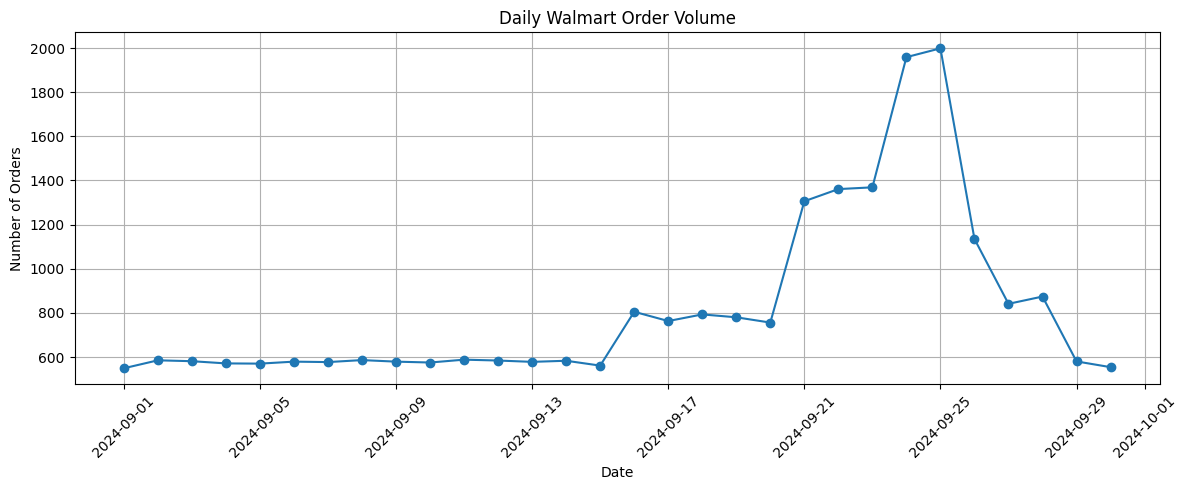

Lowest daily order volume: 549
Highest daily order volume: 1999
Average daily order volume: 817.37
Days with zero orders: 0


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

cleaned_tx["timestamp"] = pd.to_datetime(
    cleaned_tx["timestamp"], errors="coerce"
)

cleaned_tx["date"] = cleaned_tx["timestamp"].dt.date

daily_orders = (
    cleaned_tx.groupby("date")["transaction_id"]
    .nunique()
    .sort_index()
)

daily_orders.index = pd.to_datetime(daily_orders.index)

all_dates = pd.date_range(
    daily_orders.index.min(),
    daily_orders.index.max(),
    freq="D"
)

daily_orders = daily_orders.reindex(all_dates, fill_value=0)


plt.figure(figsize=(12, 5))
plt.plot(daily_orders.index, daily_orders.values, marker="o")

plt.title("Daily Walmart Order Volume")
plt.xlabel("Date")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


print("Lowest daily order volume:", daily_orders.min())
print("Highest daily order volume:", daily_orders.max())
print("Average daily order volume:", round(daily_orders.mean(), 2))
print("Days with zero orders:", (daily_orders == 0).sum())


### 6 — Self-check

Fill in what you have and leave the rest. **The required items are the team setup and the charter.** Everything else is progress we want to see, not a pass or fail. The checks are shape checks; they cannot verify your analysis is right, only that you have gotten far enough to have one.

In [ ]:

# LAB 09 — SELF-CHECK

# Verify the charter from the repository history
charter_result = subprocess.run(
    [
        "git", "-C", REPO_PATH,
        "log", "--oneline", "--", "CHARTER.md"
    ],
    capture_output=True,
    text=True
)

charter_committed = (
    charter_result.returncode == 0
    and bool(charter_result.stdout.strip())
)

required = {
    'team_setup_complete': check_team(
        team_setup, quiet=True
    ),
    'charter_committed': charter_committed,
}

progress = {
    'rows_after_cleaning': int(len(cleaned_tx)),
    'decisions_logged': int(len(decision_log)),
    'canonical_products': int(
        cleaned_tx["canonical_sku"].nunique()
    ),
    'weather_api_rows': int(len(weather_df)),
    'notebook_runs_clean': False,
}

def is_done(value):
    return not (
        value is None
        or value is False
        or (
            isinstance(value, str)
            and value.startswith('TODO')
        )
    )

def check(required, progress):
    print('REQUIRED')

    for label, value in required.items():
        print(
            '  PASS' if is_done(value) else '  FAIL',
            '-', label, '=', value
        )

    print('PROGRESS')

    for label, value in progress.items():
        print(
            '  done' if is_done(value) else '  not yet',
            '-', label, '=', value
        )

    ok = all(is_done(v) for v in required.values())

    print()
    print('required items complete:', ok)
    print(
        'progress items done:',
        sum(is_done(v) for v in progress.values()),
        'of', len(progress)
    )

    return ok

check(required, progress)


REQUIRED
  PASS - team_setup_complete = True
  PASS - charter_committed = True
PROGRESS
  done - rows_after_cleaning = 25402
  done - decisions_logged = 5
  done - canonical_products = 43
  done - weather_api_rows = 30
  not yet - notebook_runs_clean = False

required items complete: True
progress items done: 4 of 5


True


**Initial chart interpretation**

The daily order-volume chart shows variation in Walmart transactions throughout September 2024. The highest daily order count was 1,999, compared with a minimum of 549.

This variation may indicate changes in purchasing behavior, but we cannot yet conclude that Hurricane Helene caused an increase in demand.

Our next steps are to establish a normal sales baseline, compare sales before and during the hurricane period, and investigate whether inventory changes or data-quality issues explain part of the observed pattern.

Transactions with missing timestamps cannot be assigned to a specific day and are excluded from this chart.


### 7 — Risk and plan

Two questions, answered concretely.

**a)** What is the single most likely thing to go wrong in the next two weeks? Name a specific technical or team problem, not "running out of time."

**b)** What are you doing about it this week? Name who is doing it and by when.

**Biggest risk:** I think the biggest problem we might run into is cleaning the data incorrectly, especially when dealing with duplicate SKUs and negative quantities. If we make the wrong decisions, it could affect our analysis and results.

**Plan, with an owner and a date:** This week, Shreya will work on cleaning the data and documenting the decisions by Wednesday, October 28. Smera will review the cleaning decisions by Friday, October 30, so we can catch any mistakes before moving on to the analysis.

### 8 — Where each question stands

**TODO:** mark each of the five questions. These owners must match the question owners table in your charter. Be honest — this is the section I read first.

| Question | Status | Who owns it |
|---|---|---|
| Q1 demand surge | in progress | Shreya|
| Q2 SKU consolidation | in progress | Smera|
| Q3 weather correlation | not started | Eyram |
| Q4 store and geography | not started| Shreya |
| Q5 signal or artifact | not started | Eyram|

At the end of week 1, "not started" on Q4 and Q5 is expected. "Not started" on all five means come find me on Monday.